In [38]:
from langgraph.graph import StateGraph, START, END
from langgraph.store.memory import InMemoryStore
from langgraph.store.base import BaseStore
from typing import TypedDict, Literal, Annotated
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator
import uuid
import os

load_dotenv()

True

In [39]:
# LLM setup

# %%
def get_groq_llm():
    return ChatOpenAI(
        model="openai/gpt-oss-120b",
        api_key=os.getenv('GROQ_API_KEY'),
        base_url= "https://api.groq.com/openai/v1",
        temperature=0.2, max_tokens=2000
    )

In [40]:
generator_llm = get_groq_llm()
evaluator_llm = get_groq_llm()
optimizer_llm = get_groq_llm()

In [41]:
def get_groq_llm_hastag():
    return ChatOpenAI(
        model="meta-llama/llama-4-scout-17b-16e-instruct",
        api_key=os.getenv('GROQ_API_KEY'),
        base_url= "https://api.groq.com/openai/v1",
        temperature=0.2, max_tokens=500
    )

In [42]:
hasttag_llm= get_groq_llm_hastag()

In [43]:
# ---------- 2. Structured output for the evaluator ----------
class TweetEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final result.")
    feedback: str = Field(..., description="Feedback for the tweet.")

structured_evaluator_llm = evaluator_llm.with_structured_output(TweetEvaluation)

In [44]:
# ---------- 3. State ----------
class TweetState(TypedDict):
    topic: str
    tweet: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int
    hashtags:str
    tweet_history: Annotated[list[str], operator.add]

In [45]:
store = InMemoryStore()
NAMESPACE = ("approved_tweets",)   # folder name where approved tweets live



In [73]:
# hastags for this tweets
# #ai_viral
import re

def suggest_hashtgas(state:TweetState, *, store: BaseStore)->list[str]:
    """ Create hashtags based on the tweets"""
    past = store.search(NAMESPACE)
    tweets = [item.value["tweet"] for item in past]

    """Recommed relevent hastags for a tweet"""
    reponse= hasttag_llm.invoke([
        HumanMessage(content=f"""
            Suggest 3 to 5 relevant, popular hastags for this tweet.
         Rules:
                     - each hashtag start with #
        Tweet:"{tweets}
                
        """)
    ]).content

    tags= re.findall(r"#\w+",reponse)
    final=[]
    for t in tags:
        if t not in final:
            final.append(t)
    return {"hashtags": final[:5],"tweet_history": final[:5]}



In [47]:
# ---------- 5. generate node — READS long-term memory ----------
def generate_tweet(state: TweetState, *, store: BaseStore):
    past = store.search(NAMESPACE)
    past_tweets = [item.value["tweet"] for item in past]

    if past_tweets:
        memory_note = ("You already wrote these tweets before. "
                       "Do NOT repeat these jokes or styles:\n" + "\n".join(past_tweets))
    else:
        memory_note = "No past tweets yet. Be creative."

    messages = [
        SystemMessage(content="You are a funny and clever Twitter/X influencer."),
        HumanMessage(content=f"""
Write a short, original, hilarious tweet on the topic: "{state['topic']}".

{memory_note}

Rules:
- Do NOT use question-answer format.
- Max 280 characters.
- Use observational humor, irony, or relatable takes.
- Use simple, day to day english.
""")
    ]

    response = generator_llm.invoke(messages).content
    return {"tweet": response, "tweet_history": [response]}



In [48]:
# ---------- 6. evaluate node — SAVES to long-term memory ----------
def evaluate_tweet(state: TweetState, *, store: BaseStore):
    messages = [
        SystemMessage(content="You are a ruthless Twitter critic. Judge humor, originality, and format."),
        HumanMessage(content=f"""
Evaluate this tweet: "{state['tweet']}"

Reject if it is question-answer format, over 280 characters, or a boring setup-punchline joke.

Respond in structured format:
- evaluation: "approved" or "needs_improvement"
- feedback: one short paragraph on strengths and weaknesses
""")
    ]

    response = structured_evaluator_llm.invoke(messages)

    # if approved -> save to long-term memory (new key = new item)
    if response.evaluation == "approved":
        store.put(
            NAMESPACE,
            str(uuid.uuid4()),
            {"topic": state["topic"], "tweet": state["tweet"]},
        )

    return {"evaluation": response.evaluation, "feedback": response.feedback}

In [49]:
# ---------- 7. optimize node — LLM rewrites using feedback ----------
def optimize_tweet(state: TweetState):
    messages = [
        SystemMessage(content="You improve tweets for humor and virality based on feedback."),
        HumanMessage(content=f"""
Improve this tweet using the feedback.

Feedback: "{state['feedback']}"
Topic: "{state['topic']}"
Original tweet: {state['tweet']}

Rewrite it. Avoid Q&A style. Stay under 280 characters.
""")
    ]

    response = optimizer_llm.invoke(messages).content
    return {
        "tweet": response,
        "iteration": state["iteration"] + 1,
        "tweet_history": [response],
    }

In [80]:
from langgraph.types import interrupt,Command
def human_approval(state:TweetState):
    decision= interrupt({"tweet":state["tweet"],"question":"Approve this tweets?"})
    if decision == "yes":
        return {"evaluation":"approved"}
    return {"evaluation":"need_improvement"}

In [50]:

# ---------- 8. router ----------
def route_evaluation(state: TweetState):
    if state["evaluation"] == "approved" or state["iteration"] >= state["max_iteration"]:
        return "approved"
    return "needs_improvement"

In [88]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

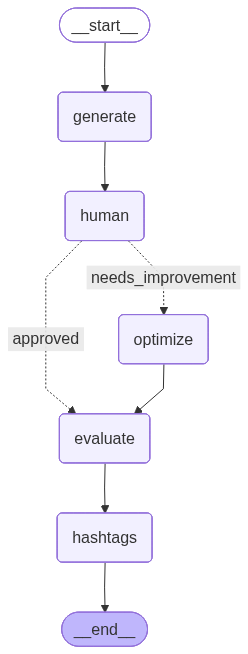

In [89]:
# ---------- 9. build + compile graph (with the store) ----------
graph = StateGraph(TweetState)

graph.add_node("generate", generate_tweet)

graph.add_node("human", human_approval)
graph.add_node("evaluate", evaluate_tweet)
graph.add_node("optimize", optimize_tweet)
graph.add_node("hashtags", suggest_hashtgas)


graph.add_edge(START, "generate")
graph.add_edge("generate", "human")
graph.add_conditional_edges("human", route_evaluation,
                            {"approved": "evaluate", "needs_improvement": "optimize"})
graph.add_edge("evaluate", "hashtags")
graph.add_edge("hashtags", END)
graph.add_edge("optimize", "evaluate")


workflow = graph.compile(store=store,checkpointer=memory)
workflow   # <-- this turns long-term memory on

In [92]:
topics = ["heart"]
config={"configurable":{"thread_id":"tweet-1"}}
result= workflow.invoke(
    {"topic":"AI Jobs","iteration":1,"max_iteration":3}, config
)

In [94]:
print(result["__interrupt__"][0].value)

{'tweet': 'The AI in HR just approved my vacation— then auto‑rejected my request because it calculated I’d be too productive on a beach. Guess even algorithms need a work‑life balance. #AIJobs', 'question': 'Approve this tweets?'}


In [102]:
result= workflow.invoke(Command(resume="yes"),config,)


In [105]:
result= workflow.invoke(Command(resume="make it shorter and funnier"),config)
result

{'topic': 'AI Jobs',
 'tweet': 'The AI in HR just approved my vacation— then auto‑rejected my request because it calculated I’d be too productive on a beach. Guess even algorithms need a work‑life balance. #AIJobs',
 'evaluation': 'approved',
 'feedback': 'The tweet delivers a clever, original punch about AI paradoxically enforcing work‑life balance, using a relatable HR scenario and a witty hashtag. It stays within the character limit and avoids a QA format, though tightening the phrasing could sharpen the comedic impact.',
 'iteration': 1,
 'max_iteration': 3,
 'hashtags': ['#RelationshipGoals',
  '#HeartProblems',
  '#LoveStruggles',
  '#AIJobs',
  '#OfficeLife'],
 'tweet_history': ['The AI in HR just approved my vacation— then auto‑rejected my request because it calculated I’d be too productive on a beach. Guess even algorithms need a work‑life balance. #AIJobs',
  '#RelationshipGoals',
  '#HeartProblems',
  '#LoveStruggles',
  '#AIJobs',
  '#OfficeLife']}

In [84]:
saved = store.search(NAMESPACE)
print("Total tweets in long-term memory:", len(saved))
for item in saved:
    print(item)

Total tweets in long-term memory: 8
Item(namespace=['approved_tweets'], key='0b476262-f293-4600-8af5-0b022a8a1f68', value={'topic': 'heart', 'tweet': 'My heart is like my Wi‑Fi: it works fine until I’m in a relationship, then it drops the signal and asks for a password I don’t have. 🚫📶❤️'}, created_at='2026-06-19T16:36:06.773797+00:00', updated_at='2026-06-19T16:36:06.773797+00:00', score=None)
Item(namespace=['approved_tweets'], key='f85e5fcc-ebfa-4969-93af-a2ccbe60299f', value={'topic': 'AI jobs', 'tweet': 'My boss just hired an AI to write my performance reviews. Now I spend my day convincing it that “thinking outside the box” isn’t a literal instruction to rearrange the office supplies. 🤖📦 #AIJobs'}, created_at='2026-06-19T16:36:10.437418+00:00', updated_at='2026-06-19T16:36:10.437418+00:00', score=None)
Item(namespace=['approved_tweets'], key='f34ab073-b3a8-4f55-aa8d-bcd4b9d76077', value={'topic': 'Monday mornings', 'tweet': 'Monday morning is the universe’s way of reminding me th

In [ ]:
#  Monday mornings feel like the universe hit the “repeat” button on the alarm, 
# the coffee, and the same tired playlist. My bed is still winning. ☕️🛌


In [ ]:
# Change a stored tweet
items = store.search(NAMESPACE)
target = items[2]
key = target.key    
print("target: ",target)
print("key: ",key)
# keep the key so we overwrite, not duplicate
old_tweet = target.value["tweet"]

new_tweet = generator_llm.invoke([
    HumanMessage(content=f"Rewrite this tweet to be more sarcastic. Under 280 chars:\n\n{old_tweet}")
]).content

store.put(NAMESPACE, key, {"topic": target.value["topic"], "tweet": new_tweet})

print("OLD:", old_tweet)
print("NEW:", store.get(NAMESPACE, key).value["tweet"])

target:  Item(namespace=['approved_tweets'], key='2ca356c8-ab46-40ee-a5b4-002cc3d502c8', value={'topic': 'Monday mornings', 'tweet': 'Monday mornings feel like the universe hit the “repeat” button on the alarm, the coffee, and the same tired playlist. My bed is still winning. ☕️🛌'}, created_at='2026-06-19T16:17:50.784900+00:00', updated_at='2026-06-19T16:17:50.784900+00:00', score=None)
key:  2ca356c8-ab46-40ee-a5b4-002cc3d502c8
OLD: Monday mornings feel like the universe hit the “repeat” button on the alarm, the coffee, and the same tired playlist. My bed is still winning. ☕️🛌
NEW: Oh great, Monday morning again—because the universe just loves hitting repeat on the alarm, the coffee, and that thrillingly original playlist. My bed, of course, is still crushing the competition. ☕️🛌


In [ ]:
items = store.search(NAMESPACE)
target = items[2]
key = target.key   
store.delete(NAMESPACE, key)

In [ ]:
saved = store.search(NAMESPACE)
print("Total tweets in long-term memory:", len(saved))
for item in saved:
    print(item.key, "|", item.value["topic"], "->", item.value["tweet"])

Total tweets in long-term memory: 2
0af4b9da-dc54-42fe-9b52-516763ae2897 | heart -> My heart is like my Wi‑Fi: it works fine until I move to the kitchen, then it drops the signal and I’m left staring at the fridge, wondering why love always needs a stronger router. 🚀❤️‍🩹
bfe5da92-4ebc-4bc9-9eff-c749e63a54c3 | AI jobs -> I told my boss I was “looking into AI jobs.” Now my coffee machine has emailed me a résumé and my toaster is begging for a reference. Apparently the only thing hiring these days is anything that can make toast. ☕🍞🤖


In [ ]:
# store.delete(NAMESPACE, key)